# Modelo 2 — LightGBM
**Projeto:** Análise comparativa de algoritmos de ML no *Credit Card Fraud Detection* (UNIVESP, 2026)

Protocolo (seção 2.4 do relatório parcial):
- mesma partição dos três modelos (`carregar_particao()`, 80/20 estratificada, semente 42);
- **sem escalonamento** (árvores não são afetadas pela escala, Quadro 3);
- ajuste de `n_estimators`, `learning_rate`, `num_leaves`, `min_child_weight`, `reg_lambda` por **CV estratificada de 5 partições só no treino, maximizando a AP**;
- **limiar escolhido pela F2 nas previsões fora-da-partição (OOF) do treino**, nunca no teste;
- teste usado **uma única vez** no fim;
- tempos de treino e inferência medidos na mesma máquina dos outros modelos.

## 1. Configuração

In [1]:
import sys, json, time, platform, os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
import sklearn
from scipy.stats import loguniform, randint, uniform
from sklearn.model_selection import StratifiedKFold, RandomizedSearchCV, cross_val_predict, cross_val_score
from sklearn.metrics import (average_precision_score, roc_auc_score, fbeta_score,
                             precision_score, recall_score, confusion_matrix,
                             precision_recall_curve, roc_curve)

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))
from src.preparo import carregar_particao, particao_temporal, preparar_dados
SEMENTE = 42
N_JOBS = 2            # fixe o MESMO número de núcleos nos três notebooks (R4)
N_ITER_BUSCA = 30     # nº de combinações testadas na busca aleatória
PASTA_RES = RAIZ / "resultados"; PASTA_RES.mkdir(exist_ok=True)
np.random.seed(SEMENTE)

print("Python", platform.python_version(), "| LightGBM", lgb.__version__, "| sklearn", sklearn.__version__)
print("CPU:", platform.processor() or platform.machine(), "| núcleos lógicos:", os.cpu_count())

Python 3.14.4 | LightGBM 4.7.0 | sklearn 1.7.2
CPU: x86_64 | núcleos lógicos: 16


## 2. Dados (mesma partição dos outros notebooks)

In [2]:
X_tr, X_te, y_tr, y_te = carregar_particao()
print(f"Treino: {len(X_tr):,} transações, {y_tr.sum()} fraudes ({y_tr.mean():.3%})")
print(f"Teste : {len(X_te):,} transações, {y_te.sum()} fraudes ({y_te.mean():.3%})")
print("Atributos:", list(X_tr.columns))
assert X_tr.shape[1] == 30

Treino: 226,980 transações, 378 fraudes (0.167%)
Teste : 56,746 transações, 95 fraudes (0.167%)
Atributos: ['V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'Horas_Dia']


## 3. Linha de base: LightGBM com parâmetros padrão
Serve de referência para mostrar quanto o ajuste melhora a AP.

In [3]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMENTE)

base = lgb.LGBMClassifier(random_state=SEMENTE, n_jobs=N_JOBS, verbose=-1)
t0 = time.perf_counter()
ap_base = cross_val_score(base, X_tr, y_tr, cv=cv, scoring="average_precision", n_jobs=1)
print(f"AP (CV) padrão: {ap_base.mean():.4f} ± {ap_base.std():.4f}  [{time.perf_counter()-t0:.0f}s]")

AP (CV) padrão: 0.4742 ± 0.1435  [6s]


## 4. Otimização dos hiperparâmetros (Quadro 3)
Busca aleatória com 5 folds, `scoring='average_precision'`. Espaço:

| Hiperparâmetro | Faixa | Por quê |
|---|---|---|
| `n_estimators` | 100–1000 | nº de árvores |
| `learning_rate` | 0,005–0,2 (log) | passo de cada árvore; menor pede mais árvores |
| `num_leaves` | 8–128 | complexidade de cada árvore |
| `min_child_weight` | 1e-3–10 (log) | soma mínima de hessiana por folha; com 378 fraudes, impede folhas "decoradas" |
| `reg_lambda` | 1e-3–10 (log) | regularização L2 |

`subsample=0.8` (com `subsample_freq=1`) e `colsample_bytree=0.8` ficam **fixos** para reduzir variância sem inflar o espaço.
Não usamos rebalanceamento: o Quadro 2 alerta para a distorção das probabilidades e o limiar será escolhido explicitamente.

In [4]:
espaco = {
    "n_estimators": randint(100, 1001),
    "learning_rate": loguniform(5e-3, 0.2),
    "num_leaves": randint(8, 129),
    "min_child_weight": loguniform(1e-3, 10),
    "reg_lambda": loguniform(1e-3, 10),
}
modelo = lgb.LGBMClassifier(subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
                            random_state=SEMENTE, n_jobs=N_JOBS, verbose=-1)
busca = RandomizedSearchCV(modelo, espaco, n_iter=N_ITER_BUSCA, scoring="average_precision",
                           cv=cv, random_state=SEMENTE, n_jobs=1, refit=False, verbose=1)
t0 = time.perf_counter()
busca.fit(X_tr, y_tr)
tempo_busca = time.perf_counter() - t0

res = pd.DataFrame(busca.cv_results_).sort_values("rank_test_score")
cols = ["param_n_estimators","param_learning_rate","param_num_leaves","param_min_child_weight",
        "param_reg_lambda","mean_test_score","std_test_score","mean_fit_time"]
res[cols].to_csv(PASTA_RES / "lightgbm_busca.csv", index=False)
print(f"Busca: {tempo_busca/60:.1f} min")
melhores = busca.best_params_
print("Melhores parâmetros:", melhores)
print(f"AP (CV) ajustado: {busca.best_score_:.4f} ± {res.iloc[0]['std_test_score']:.4f}")
res[cols].head(10)

Fitting 5 folds for each of 30 candidates, totalling 150 fits
Busca: 12.4 min
Melhores parâmetros: {'learning_rate': np.float64(0.009793166754027884), 'min_child_weight': np.float64(1.050619945159704), 'n_estimators': 489, 'num_leaves': 61, 'reg_lambda': np.float64(0.1537592023548176)}
AP (CV) ajustado: 0.8532 ± 0.0281


,param_n_estimators,param_learning_rate,param_num_leaves,param_min_child_weight,param_reg_lambda,mean_test_score,std_test_score,mean_fit_time
11,489,0.009793,61,1.050620,0.153759,0.853170,0.028080,4.415863
4,847,0.015360,96,0.125610,0.014619,0.852848,0.030807,7.410413
25,584,0.039937,30,0.605431,0.261619,0.852501,0.028448,4.658371
6,662,0.026892,115,1.382623,0.114009,0.852311,0.031974,5.435121
18,388,0.067826,12,0.824193,5.072283,0.851458,0.024916,3.206118
20,673,0.007109,95,0.030428,0.460988,0.851140,0.027081,5.847035
15,316,0.013605,67,2.065143,0.148178,0.850598,0.026663,2.788416
2,761,0.045919,60,0.679658,7.579480,0.850518,0.025411,6.238540
0,206,0.019907,79,6.351221,0.248104,0.848387,0.029435,1.789669
19,300,0.055212,79,4.569185,0.062777,0.848243,0.026970,2.680176


## 5. Escolha do limiar pela F2 (só no treino)
Previsões **fora-da-partição** (cada transação do treino é prevista pelo modelo que não a viu).
O limiar que maximiza a F2 nessas previsões é congelado e depois aplicado ao teste.
As AP por fold também são guardadas para o teste t corrigido na comparação entre modelos.

In [5]:
final = lgb.LGBMClassifier(**melhores, subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
                           random_state=SEMENTE, n_jobs=N_JOBS, verbose=-1)
p_oof = cross_val_predict(final, X_tr, y_tr, cv=cv, method="predict_proba", n_jobs=1)[:, 1]

ap_folds = [average_precision_score(y_tr.iloc[va], p_oof[va]) for _, va in cv.split(X_tr, y_tr)]
print("AP por fold:", np.round(ap_folds, 4))

prec, rec, lim = precision_recall_curve(y_tr, p_oof)
f2 = 5 * prec * rec / (4 * prec + rec + 1e-12)
i = np.nanargmax(f2[:-1])
LIMIAR = float(lim[i])
print(f"Limiar F2 = {LIMIAR:.4f}  (OOF: F2={f2[i]:.4f}, precisão={prec[i]:.4f}, recall={rec[i]:.4f})")

AP por fold: [0.8491 0.8681 0.8006 0.8798 0.8682]
Limiar F2 = 0.1236  (OOF: F2=0.8512, precisão=0.8933, recall=0.8413)


## 6. Treino final e custo computacional

In [6]:
t0 = time.perf_counter(); final.fit(X_tr, y_tr); tempo_treino = time.perf_counter() - t0

# inferência: mediana de 5 repetições no conjunto de teste inteiro
tempos = []
for _ in range(5):
    t0 = time.perf_counter(); p_te = final.predict_proba(X_te)[:, 1]; tempos.append(time.perf_counter() - t0)
tempo_inf = float(np.median(tempos))
print(f"Treino: {tempo_treino:.2f} s | Inferência ({len(X_te):,} transações): {tempo_inf*1000:.1f} ms "
      f"= {tempo_inf/len(X_te)*1e6:.2f} µs/transação")

Treino: 5.25 s | Inferência (56,746 transações): 683.4 ms = 12.04 µs/transação


## 7. Avaliação final no teste (uma única vez)

In [7]:
y_hat = (p_te >= LIMIAR).astype(int)
vn, fp, fn, vp = confusion_matrix(y_te, y_hat).ravel()
metricas = {
    "average_precision": average_precision_score(y_te, p_te),
    "roc_auc": roc_auc_score(y_te, p_te),
    "f2": fbeta_score(y_te, y_hat, beta=2),
    "precisao": precision_score(y_te, y_hat, zero_division=0),
    "recall": recall_score(y_te, y_hat),
    "VN": int(vn), "FP": int(fp), "FN": int(fn), "VP": int(vp),
}
print(f"""LightGBM
Average Precision: {metricas['average_precision']:.4f}
ROC-AUC: {metricas['roc_auc']:.4f}
F2: {metricas['f2']:.4f}
Precisão: {metricas['precisao']:.4f} | Recall: {metricas['recall']:.4f}
Verdadeiros negativos: {vn} | Falsos positivos: {fp} | Falsos negativos: {fn} | Verdadeiros positivos: {vp}""")

LightGBM
Average Precision: 0.8224
ROC-AUC: 0.9745
F2: 0.7826
Precisão: 0.9000 | Recall: 0.7579
Verdadeiros negativos: 56643 | Falsos positivos: 8 | Falsos negativos: 23 | Verdadeiros positivos: 72


### 7.1 Intervalo de confiança da AP (bootstrap estratificado, 1000 reamostragens)

In [8]:
rng = np.random.default_rng(SEMENTE)
yv, pv = y_te.to_numpy(), p_te
pos, neg = np.where(yv == 1)[0], np.where(yv == 0)[0]
boot = []
for _ in range(1000):
    idx = np.concatenate([rng.choice(pos, len(pos)), rng.choice(neg, len(neg))])
    boot.append(average_precision_score(yv[idx], pv[idx]))
ic = np.percentile(boot, [2.5, 97.5])
print(f"AP teste = {metricas['average_precision']:.4f}  IC95% [{ic[0]:.4f}; {ic[1]:.4f}]")

AP teste = 0.8224  IC95% [0.7492; 0.8911]


### 7.2 Curvas e importância dos atributos

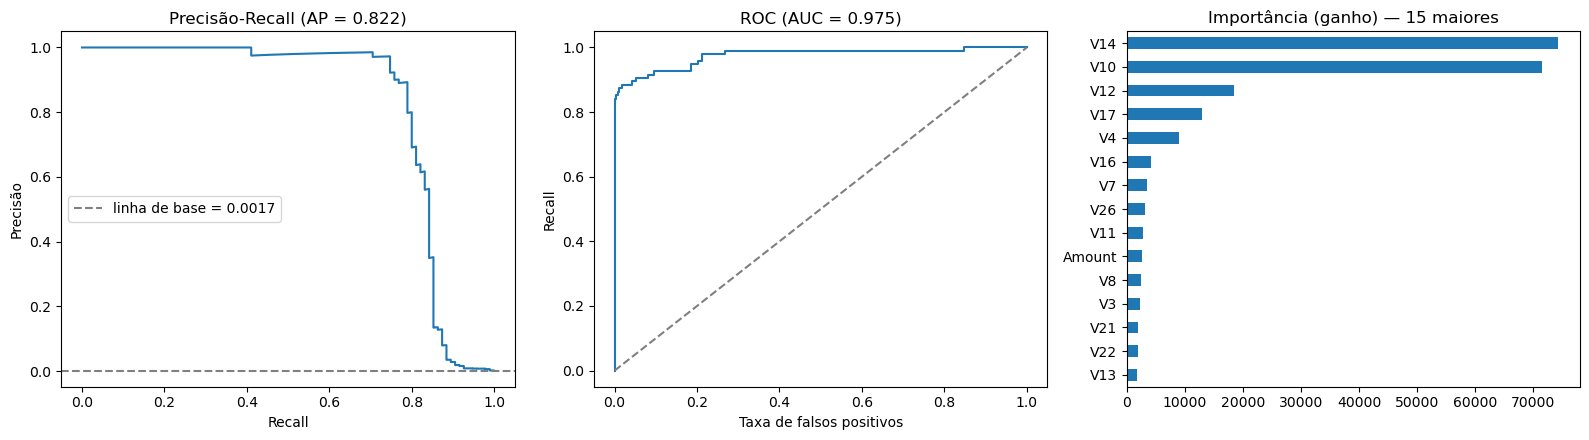

In [9]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
pr, rc, _ = precision_recall_curve(y_te, p_te)
ax[0].plot(rc, pr); ax[0].axhline(y_te.mean(), ls="--", c="gray", label=f"linha de base = {y_te.mean():.4f}")
ax[0].set(xlabel="Recall", ylabel="Precisão", title=f"Precisão-Recall (AP = {metricas['average_precision']:.3f})"); ax[0].legend()
fpr, tpr, _ = roc_curve(y_te, p_te)
ax[1].plot(fpr, tpr); ax[1].plot([0,1],[0,1],"--",c="gray")
ax[1].set(xlabel="Taxa de falsos positivos", ylabel="Recall", title=f"ROC (AUC = {metricas['roc_auc']:.3f})")
imp = pd.Series(final.booster_.feature_importance("gain"), index=X_tr.columns).sort_values().tail(15)
imp.plot.barh(ax=ax[2], title="Importância (ganho) — 15 maiores")
plt.tight_layout(); plt.savefig(PASTA_RES / "lightgbm_curvas.png", dpi=150); plt.show()

## 8. Robustez: partição temporal (R5)
Treina nos primeiros 80% das transações (ordem de `Time`) e testa nos 20% finais, com os **mesmos hiperparâmetros e o mesmo limiar**.
Se a AP cair muito em relação ao item 7, parte do resultado aleatório vinha das rajadas de fraude.

In [10]:
Xt_tr, Xt_te, yt_tr, yt_te = particao_temporal(preparar_dados())
mt = lgb.LGBMClassifier(**melhores, subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
                        random_state=SEMENTE, n_jobs=N_JOBS, verbose=-1).fit(Xt_tr, yt_tr)
pt = mt.predict_proba(Xt_te)[:, 1]; yt_hat = (pt >= LIMIAR).astype(int)
temporal = {"average_precision": average_precision_score(yt_te, pt), "roc_auc": roc_auc_score(yt_te, pt),
            "f2": fbeta_score(yt_te, yt_hat, beta=2), "precisao": precision_score(yt_te, yt_hat, zero_division=0),
            "recall": recall_score(yt_te, yt_hat), "fraudes_teste": int(yt_te.sum())}
print({k: round(v, 4) if isinstance(v, float) else v for k, v in temporal.items()})

{'average_precision': 0.809, 'roc_auc': 0.9898, 'f2': 0.7787, 'precisao': 0.8143, 'recall': 0.7703, 'fraudes_teste': 74}


## 9. Salvar resultados para o notebook de comparação

In [11]:
saida = {
    "modelo": "LightGBM",
    "melhores_parametros": {k: (float(v) if isinstance(v, (float, np.floating)) else int(v)) for k, v in melhores.items()},
    "ap_cv_padrao": float(ap_base.mean()), "ap_cv_ajustado": float(busca.best_score_),
    "ap_folds": [float(a) for a in ap_folds], "limiar_f2": LIMIAR,
    "teste": {k: (float(v) if isinstance(v, (float, np.floating)) else v) for k, v in metricas.items()},
    "ap_teste_ic95": [float(ic[0]), float(ic[1])],
    "temporal": {k: float(v) for k, v in temporal.items()},
    "tempo_busca_s": tempo_busca, "tempo_treino_s": tempo_treino, "tempo_inferencia_s": tempo_inf,
    "n_jobs": N_JOBS, "lightgbm": lgb.__version__,
}
(PASTA_RES / "lightgbm_resultados.json").write_text(json.dumps(saida, indent=2, ensure_ascii=False))
np.save(PASTA_RES / "lightgbm_proba_teste.npy", p_te)
print(json.dumps(saida, indent=2, ensure_ascii=False))

{
  "modelo": "LightGBM",
  "melhores_parametros": {
    "learning_rate": 0.009793166754027884,
    "min_child_weight": 1.050619945159704,
    "n_estimators": 489,
    "num_leaves": 61,
    "reg_lambda": 0.1537592023548176
  },
  "ap_cv_padrao": 0.47415879375718895,
  "ap_cv_ajustado": 0.8531704205586446,
  "ap_folds": [
    0.8490904028275466,
    0.8681141696015943,
    0.8005893285253934,
    0.8798426770650373,
    0.8682155247736513
  ],
  "limiar_f2": 0.12356452519062402,
  "teste": {
    "average_precision": 0.8224083614444617,
    "roc_auc": 0.9745096709399843,
    "f2": 0.782608695652174,
    "precisao": 0.9,
    "recall": 0.7578947368421053,
    "VN": 56643,
    "FP": 8,
    "FN": 23,
    "VP": 72
  },
  "ap_teste_ic95": [
    0.7491864571671782,
    0.8910510329135142
  ],
  "temporal": {
    "average_precision": 0.8090273284014866,
    "roc_auc": 0.9897519541775762,
    "f2": 0.7786885245901639,
    "precisao": 0.8142857142857143,
    "recall": 0.7702702702702703,
    "frau